In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("smartcart_customers.csv")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [4]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

## data preprocessing

## 1. handle missing values

In [5]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [6]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


## feature engineering

In [7]:
# age
df["age"] = 2026-df["Year_Birth"]

In [8]:
# customer joining  date
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

referance_date = df["Dt_Customer"].max()

df["customer_tenure_days"] = (referance_date - df["Dt_Customer"]).dt.days

In [9]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'age', 'customer_tenure_days'],
      dtype='str')

In [10]:
#spendings 

df["total_spending"] = df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [11]:
# children
df["total_children"] = df["Kidhome"] + df["Teenhome"]

In [12]:
#education

df["Education"] = df["Education"].replace({
    "2n Cycle" : "undergraduate", "Basic" : "undergraduate",
    "Graduation" : "graduate",
    "PhD" : "postgraduate", "Master" : "postgraduate"
})

In [13]:
#marital status

df["living_with"] = df["Marital_Status"].replace({
    "Married" : "partner", "Together" : "partner",
    "Single" : "Alone",
    "Divorced" : "Alone", "Widow" : "Alone", "YOLO": "Alone", "Absurd" : "Alone"
})

## drop columns

In [14]:
cols = ["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer"]
spending_cols = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]

cols_to_drop = cols + spending_cols

df_cleaned = df.drop(columns=cols_to_drop)

In [15]:
df_cleaned.shape

(2240, 15)

In [16]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,customer_tenure_days,total_spending,total_children,living_with
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,partner
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,partner
4,postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,partner


## outliers

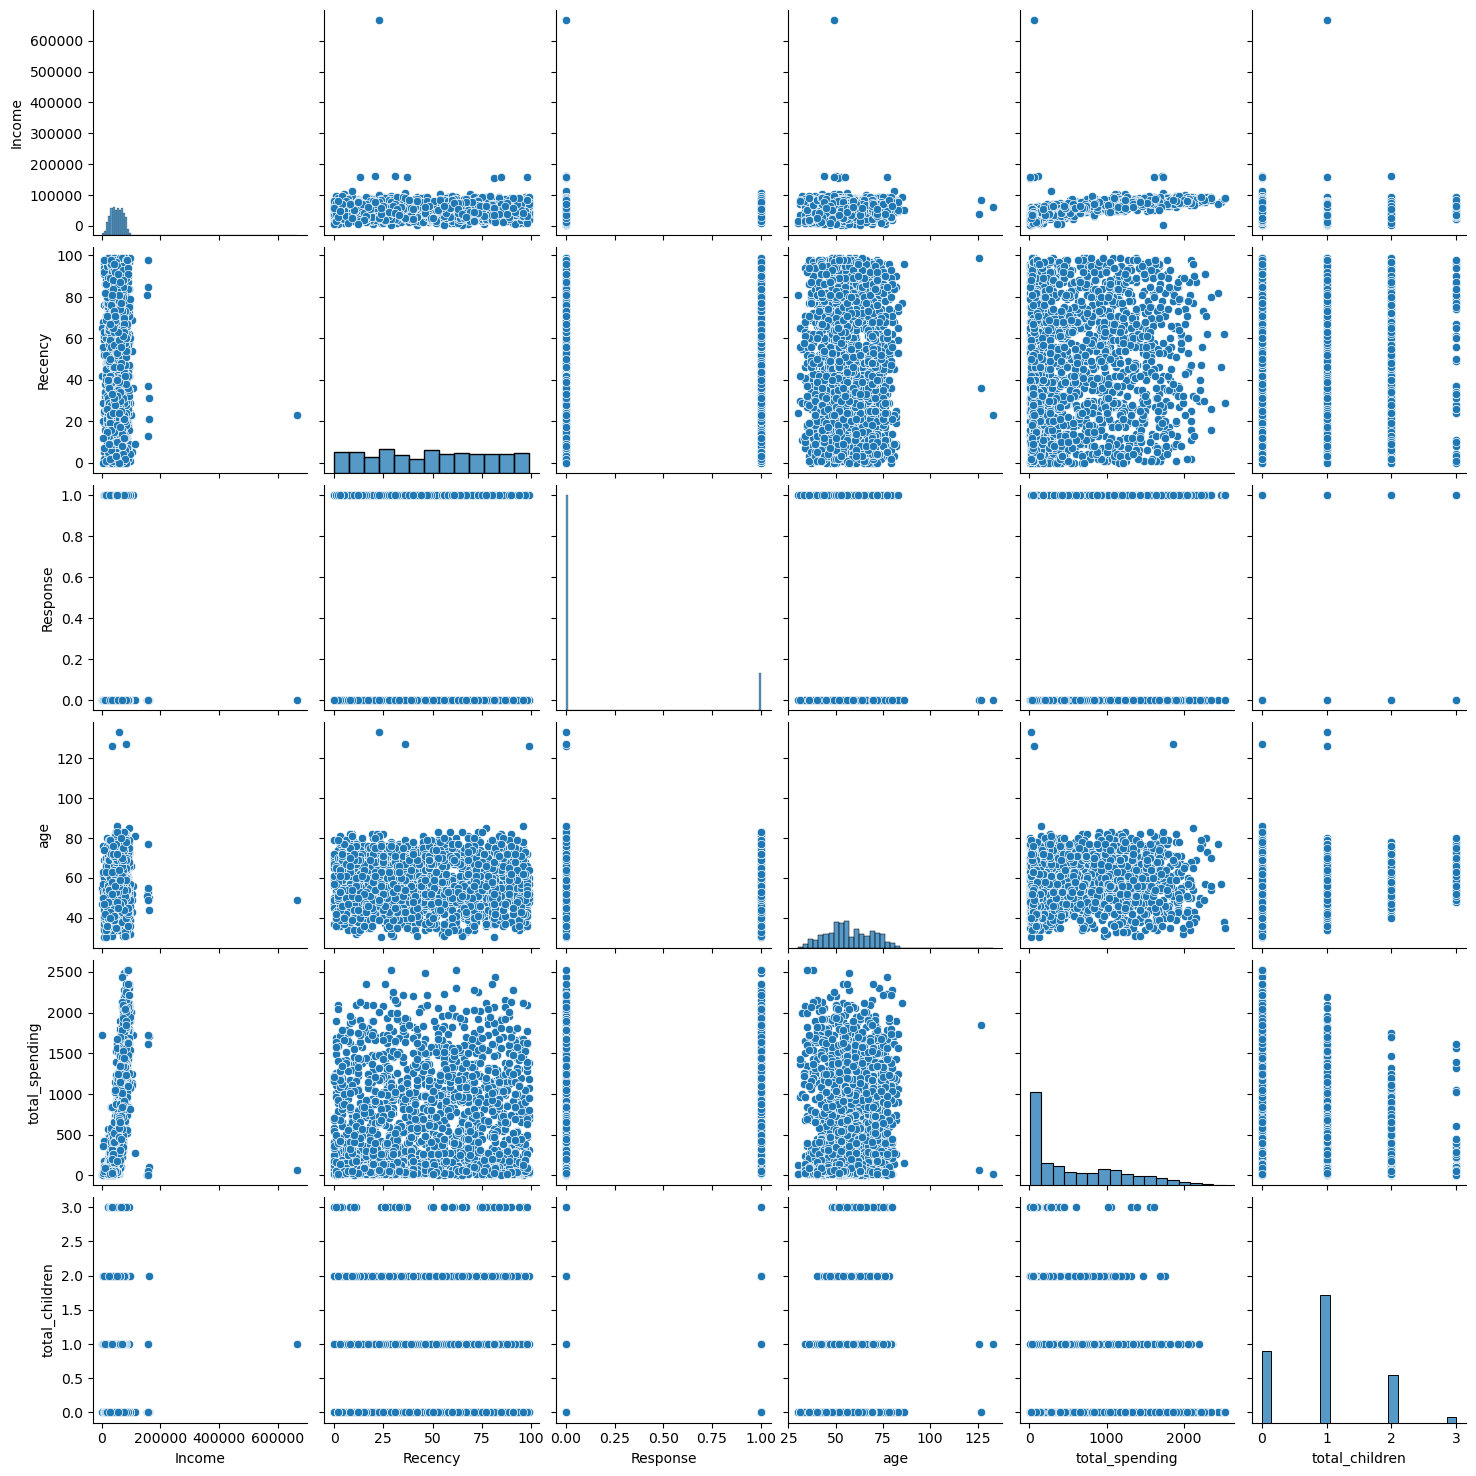

In [17]:
cols = ["Income","Recency","Response","age","total_spending","total_children"]

#relative plots of some features -- pair plots
sns.pairplot(df_cleaned[cols])

In [18]:
# remove outliers 

print("data size with outliers : ", len(df_cleaned))

df_cleaned = df_cleaned[(df_cleaned["age"] < 90 )]
df_cleaned = df_cleaned[(df_cleaned["Income"] < 600_000 )]

print("data size without outliers : ", len(df_cleaned))

data size with outliers :  2240
data size without outliers :  2236


## heatmap

In [19]:
corr = df_cleaned.corr(numeric_only=True)

<Axes: >

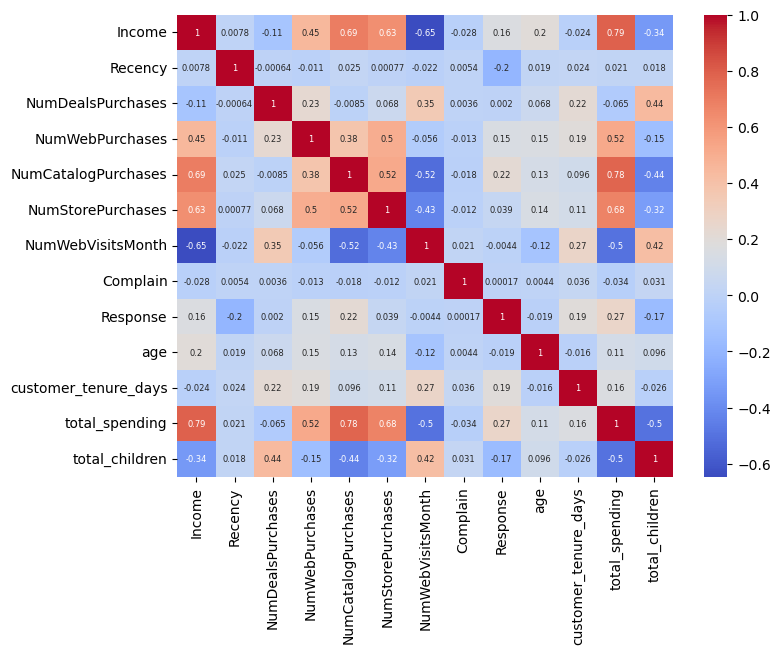

In [20]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    annot_kws = {"size":6},
    cmap="coolwarm"
)

## Encoding

In [21]:
from sklearn.preprocessing import OneHotEncoder

In [22]:
ohe = OneHotEncoder()

cat_col = ["Education","living_with"]

enc_col = ohe.fit_transform(df_cleaned[cat_col])

In [23]:
enc_df = pd.DataFrame(enc_col.toarray(), columns = ohe.get_feature_names_out(cat_col), index=df_cleaned.index)

In [24]:
enc_df.head()

,Education_graduate,Education_postgraduate,Education_undergraduate,living_with_Alone,living_with_partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [25]:
enc_df.shape

(2236, 5)

In [26]:
df_encoded = pd.concat([df_cleaned.drop(columns=cat_col),enc_df], axis =1)

In [27]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,customer_tenure_days,total_spending,total_children,Education_graduate,Education_postgraduate,Education_undergraduate,living_with_Alone,living_with_partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


In [28]:
df_encoded.shape

(2236, 18)

## scaling

In [29]:
from sklearn.preprocessing import StandardScaler

In [30]:
X = df_encoded.drop(columns=["Response"])  # Keep campaign response out of clustering


In [31]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## visualize

In [32]:
X_scaled.shape

(2236, 17)

In [33]:
#2D
from sklearn.decomposition import PCA

pca=PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


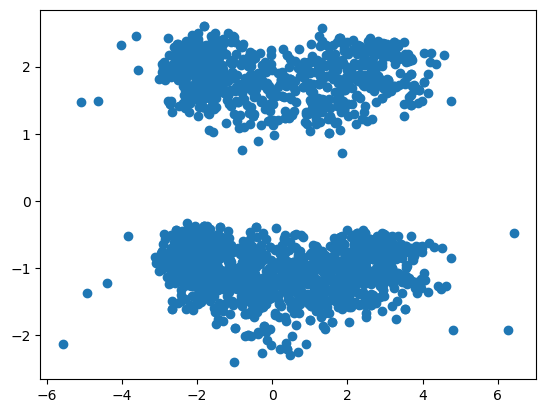

In [34]:
plt.scatter( X_pca[:,0] , X_pca[:,1] )

In [35]:
pca.explained_variance_ratio_

array([0.24224871, 0.11841125])

In [36]:
#3D
from sklearn.decomposition import PCA

pca=PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

In [37]:
pca.explained_variance_ratio_

array([0.24224871, 0.11841125, 0.10904012])

Text(0.5, 0.92, '3D projection')

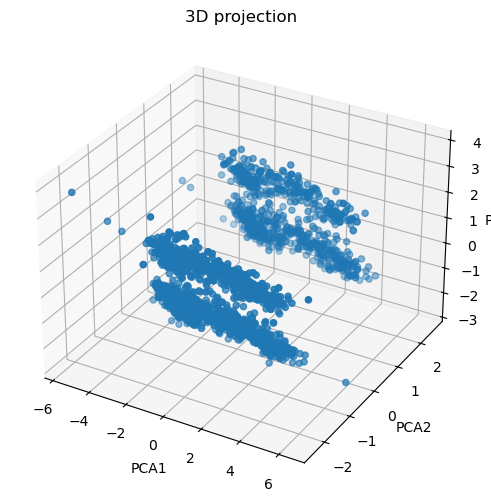

In [38]:
fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter( X_pca[:,0] , X_pca[:,1], X_pca[:,2] )

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D projection")

## analyze k value

## 1. elbow method

In [39]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [40]:
knee = KneeLocator(range(1,11), wcss, curve="convex", direction="decreasing")
knee.elbow

np.int64(4)

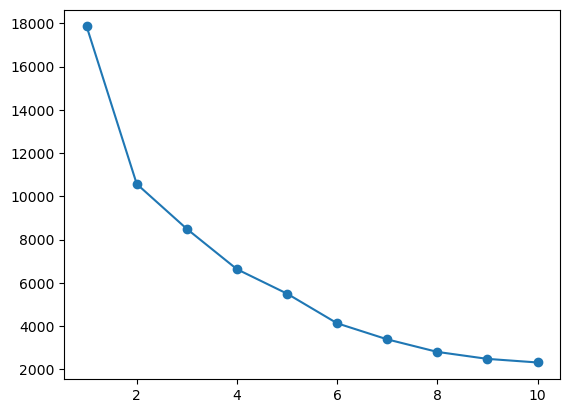

In [41]:
#plot

plt.plot(range(1,11), wcss, marker="o")

## 2. silhouette score

In [42]:
from sklearn.metrics import silhouette_score

scores =[]

for k in range(2,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_pca)
    score= silhouette_score(X_pca, labels)
    scores.append(score)

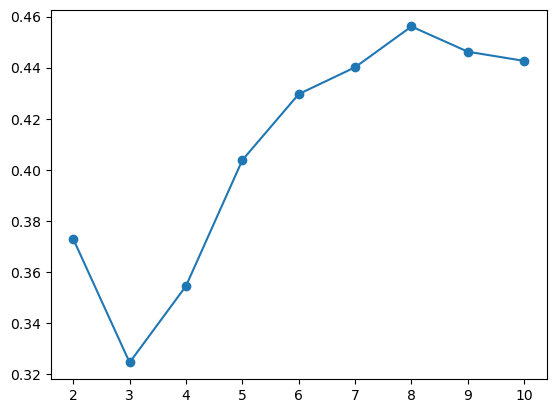

In [43]:
#plot
plt.plot(range(2,11), scores , marker ="o")

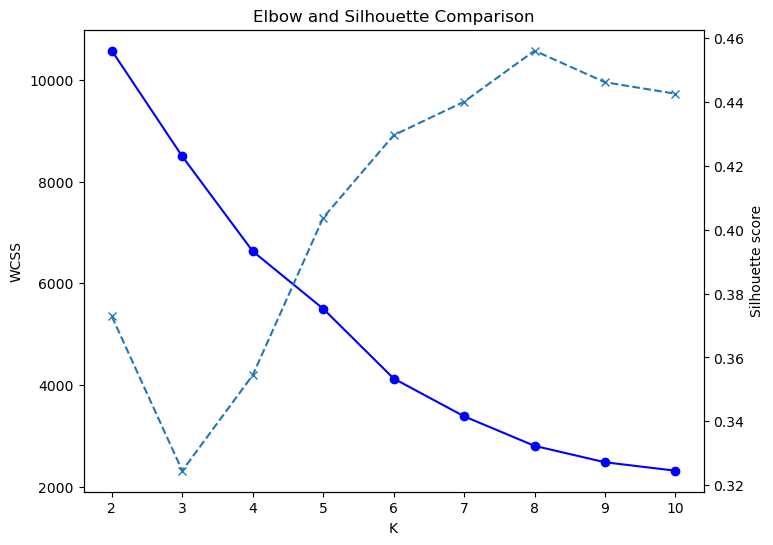

In [44]:
# Combined elbow and silhouette plots (both use matching k values)
k_range = range(2, 11)

fig, ax1 = plt.subplots(figsize=(8,6))
ax1.plot(k_range, wcss[1:], marker="o", color="blue")
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range, scores, marker="x", linestyle="--")
ax2.set_ylabel("Silhouette score")
plt.title("Elbow and Silhouette Comparison")
plt.show()


## clustering

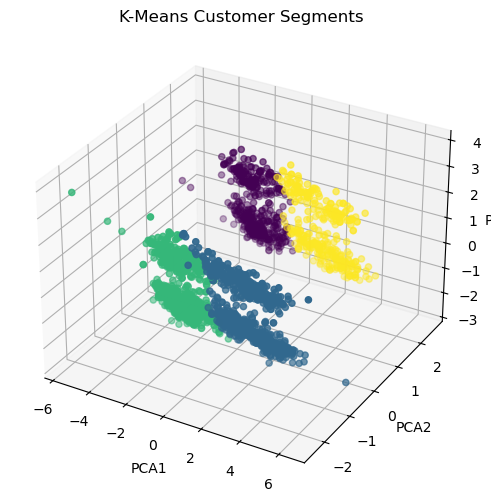

In [45]:
# K-Means clustering (primary model)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
label_kmeans = kmeans.fit_predict(X_pca)

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c=label_kmeans)
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("K-Means Customer Segments")
plt.show()


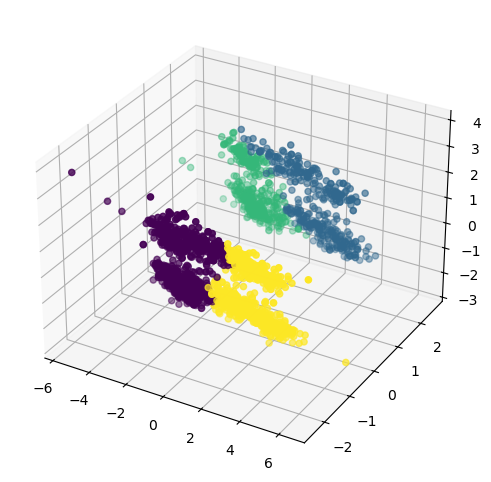

In [46]:
#agglomerarive clustering
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=4, linkage="ward")
agg_labels = agg.fit_predict(X_pca)

fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111, projection="3d")

ax.scatter( X_pca[:,0] , X_pca[:,1], X_pca[:,2], c=agg_labels )

## characterization of clusters

In [47]:
# Characterize customers using the original cleaned features, not encoded X
# Response is retained here only for post-clustering campaign analysis.
df_clustered = df_cleaned.loc[X.index].copy()
df_clustered["clusters"] = label_kmeans


In [48]:
df_clustered.head()


,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,age,customer_tenure_days,total_spending,total_children,living_with,clusters
0,graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone,3
1,graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone,0
2,graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,partner,1
3,graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,partner,2
4,postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,partner,2


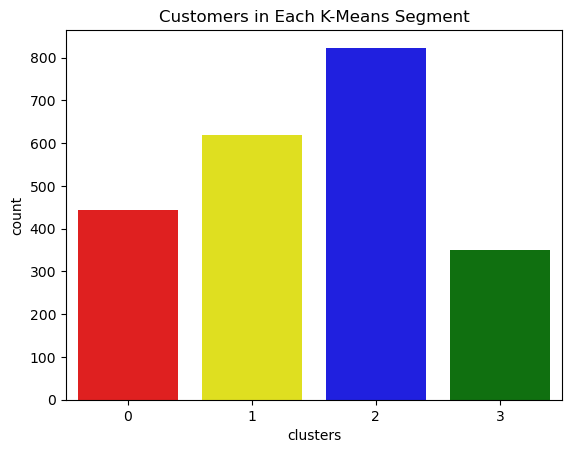

In [49]:
pal = ["red", "yellow", "blue", "green"]
sns.countplot(data=df_clustered, x="clusters", palette=pal, hue="clusters", legend=False)
plt.title("Customers in Each K-Means Segment")
plt.show()


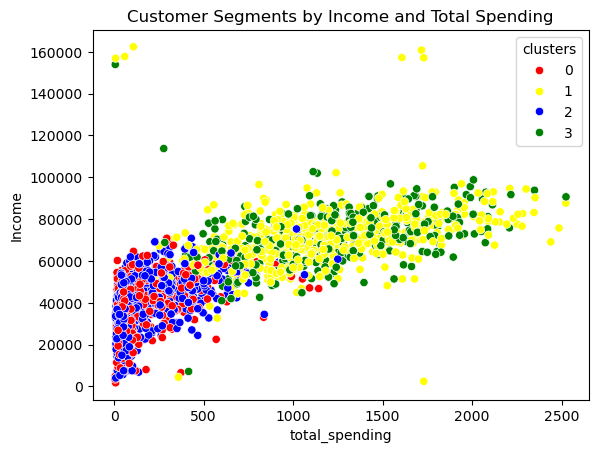

In [50]:
# Income and spending patterns
sns.scatterplot(data=df_clustered, x="total_spending", y="Income", hue="clusters", palette=pal)
plt.title("Customer Segments by Income and Total Spending")
plt.show()


In [51]:
# Segment summary based on original customer features
cluster_summary = df_clustered.groupby("clusters").mean(numeric_only=True)
print(cluster_summary.round(2))


            Income  Recency  NumDealsPurchases  NumWebPurchases  \
clusters                                                          
0         37175.74    48.24               2.58             2.74   
1         71016.13    48.82               2.11             5.68   
2         37482.57    49.20               2.56             2.88   
3         70911.82    50.54               1.84             5.80   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
clusters                                                                        
0                        0.86               3.65               6.58      0.01   
1                        5.12               8.53               3.70      0.01   
2                        0.78               3.76               6.54      0.01   
3                        5.02               8.45               3.70      0.01   

          Response    age  customer_tenure_days  total_spending  \
clusters                                   

## deployment files
Run these final cells after running the notebook from the top. They save the segment labels and summary for the Streamlit dashboard.

In [52]:
# Save the customer-level results and cluster summary for Streamlit
df_clustered.to_csv("smartcart_segmented_customers.csv", index=False)
cluster_summary.to_csv("cluster_summary.csv")

print("Saved smartcart_segmented_customers.csv")
print("Saved cluster_summary.csv")


Saved smartcart_segmented_customers.csv
Saved cluster_summary.csv


In [53]:
# Final quality checks
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

print("Rows segmented:", len(df_clustered))
print("Number of clusters:", df_clustered["clusters"].nunique())
print("Silhouette score:", round(silhouette_score(X_pca, label_kmeans), 4))
print("Davies-Bouldin score:", round(davies_bouldin_score(X_pca, label_kmeans), 4))
print("Calinski-Harabasz score:", round(calinski_harabasz_score(X_pca, label_kmeans), 2))


Rows segmented: 2236
Number of clusters: 4
Silhouette score: 0.4082
Davies-Bouldin score: 1.0404
Calinski-Harabasz score: 1428.2
